# Implementasi Clustering untuk Menemukan Pola pada Data Performa Siswa
## Metodologi CRISP-DM (Cross-Industry Standard Process for Data Mining)

**Dataset:** `student_performance_updated_1000.csv` (1000 baris data siswa)

Notebook ini menyusun seluruh tahapan CRISP-DM secara berurutan:
1. Business Understanding
2. Data Understanding
3. Data Preparation
4. Modeling
5. Evaluation
6. Deployment


## 1. Business Understanding

### 1.1 Latar Belakang
Sebuah lembaga pendidikan ingin memahami **pola performa dan keterlibatan (engagement) siswa** secara
lebih mendalam. Selama ini pihak sekolah hanya melihat nilai akhir (Final Grade) siswa secara individual,
tanpa memahami adanya **kelompok-kelompok siswa dengan karakteristik belajar yang mirip**. Padahal,
jika kelompok-kelompok tersebut dapat diidentifikasi, sekolah bisa merancang **intervensi yang lebih
tepat sasaran** (misalnya kelas remedial, program mentoring, atau apresiasi bagi siswa berprestasi).

### 1.2 Tujuan Bisnis (Business Objectives)
- Menemukan segmen/kelompok siswa berdasarkan pola kehadiran, jam belajar, nilai sebelumnya, nilai
  akhir, keikutsertaan ekstrakurikuler, dan dukungan orang tua.
- Memberikan insight yang dapat ditindaklanjuti (actionable) oleh pihak sekolah/guru, misalnya:
  - Siswa dengan performa tinggi dan konsisten → dipertahankan/diberi pengayaan.
  - Siswa dengan performa rendah namun jam belajar rendah → perlu motivasi & pendampingan.
  - Siswa dengan kehadiran rendah → perlu pendekatan disiplin/konseling.

### 1.3 Tujuan Data Mining (Data Mining Goals)
- Menggunakan algoritma **clustering (unsupervised learning)**, karena tidak ada label kelas yang
  menyatakan "kelompok siswa" secara eksplisit di dalam data — pola ini harus ditemukan sendiri oleh
  algoritma.
- Algoritma utama: **K-Means Clustering**, dibandingkan dengan **Hierarchical (Agglomerative)
  Clustering** sebagai pembanding.
- Menentukan jumlah cluster optimal menggunakan **Elbow Method** dan **Silhouette Score**.

### 1.4 Kriteria Keberhasilan (Success Criteria)
- Diperoleh cluster yang memiliki **silhouette score** yang wajar (> 0.3 dianggap struktur cluster
  cukup baik untuk data sosial/perilaku seperti ini).
- Setiap cluster dapat **diinterpretasikan secara bisnis** (memiliki karakteristik/profil yang jelas
  dan masuk akal, bukan sekadar angka).
- Model dapat **di-deploy** menjadi aplikasi sederhana agar guru/staf non-teknis dapat memakainya untuk
  memprediksi cluster siswa baru.


## 2. Data Understanding

Tahap ini bertujuan untuk mengenali struktur data, kualitas data (missing value, outlier, duplikasi),
serta memahami distribusi dan hubungan antar variabel sebelum data diolah lebih lanjut.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

df_raw = pd.read_csv('student_performance_updated_1000.csv')
print("Ukuran data:", df_raw.shape)
df_raw.head()


Ukuran data: (1000, 12)


,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
0,1.0,John,Male,85.0,15.0,78.0,1.0,High,80.0,4.8,59.0,False
1,2.0,Sarah,Female,90.0,20.0,85.0,2.0,Medium,87.0,2.2,70.0,True
2,3.0,Alex,Male,78.0,10.0,65.0,0.0,Low,68.0,4.6,92.0,False
3,4.0,Michael,Male,92.0,25.0,90.0,3.0,High,92.0,2.9,96.0,False
4,5.0,Emma,Female,NaN,18.0,82.0,2.0,Medium,85.0,4.1,97.0,True


In [2]:
# Informasi tipe data & jumlah non-null
df_raw.info()


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   StudentID                  960 non-null    float64
 1   Name                       966 non-null    str    
 2   Gender                     952 non-null    str    
 3   AttendanceRate             960 non-null    float64
 4   StudyHoursPerWeek          950 non-null    float64
 5   PreviousGrade              967 non-null    float64
 6   ExtracurricularActivities  957 non-null    float64
 7   ParentalSupport            978 non-null    str    
 8   FinalGrade                 960 non-null    float64
 9   Study Hours                976 non-null    float64
 10  Attendance (%)             959 non-null    float64
 11  Online Classes Taken       975 non-null    object 
dtypes: float64(8), object(1), str(3)
memory usage: 115.5+ KB


In [3]:
# Statistik deskriptif untuk kolom numerik
df_raw.describe()


,StudentID,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,FinalGrade,Study Hours,Attendance (%)
count,960.000000,960.000000,950.000000,967.000000,957.000000,960.000000,976.000000,959.000000
mean,5416.019792,85.510417,17.630526,77.598759,1.520376,80.030208,2.406967,77.248175
std,2653.748319,7.332125,6.272132,10.006640,1.046439,9.493652,1.620267,19.298148
min,1.000000,70.000000,8.000000,60.000000,0.000000,62.000000,-5.000000,50.000000
25%,3113.500000,82.000000,12.000000,70.000000,1.000000,72.000000,1.200000,63.000000
50%,5396.500000,88.000000,18.000000,78.000000,1.000000,80.000000,2.500000,76.000000
75%,7754.750000,91.000000,22.000000,86.000000,2.000000,88.000000,3.700000,89.000000
max,9998.000000,95.000000,30.000000,90.000000,3.000000,92.000000,5.000000,200.000000


### 2.1 Deskripsi Variabel

| Kolom | Deskripsi |
|---|---|
| StudentID | ID unik siswa |
| Name | Nama siswa |
| Gender | Jenis kelamin |
| AttendanceRate | Persentase kehadiran (versi 1) |
| StudyHoursPerWeek | Jam belajar per minggu (versi 1) |
| PreviousGrade | Nilai sebelumnya |
| ExtracurricularActivities | Jumlah kegiatan ekstrakurikuler yang diikuti |
| ParentalSupport | Tingkat dukungan orang tua (Low/Medium/High) |
| FinalGrade | Nilai akhir |
| Study Hours | Jam belajar (versi 2, berbeda sumber) |
| Attendance (%) | Persentase kehadiran (versi 2, berbeda sumber) |
| Online Classes Taken | Apakah siswa mengikuti kelas online (True/False) |

Dataset ini memuat **dua pasang kolom yang tampak serupa** (`AttendanceRate` vs `Attendance (%)`,
dan `StudyHoursPerWeek` vs `Study Hours`), namun ternyata berasal dari sumber/proses input yang
berbeda dan **tidak berkorelasi** satu sama lain (dicek pada sel berikutnya). Ini adalah kasus umum
pada data dunia nyata: ada duplikasi konsep kolom yang harus diselidiki dan diputuskan mana yang
dipakai pada tahap Data Preparation.


In [4]:
# Cek missing value per kolom
missing = df_raw.isnull().sum().sort_values(ascending=False)
missing_pct = (missing / len(df_raw) * 100).round(2)
pd.DataFrame({'jumlah_missing': missing, 'persentase(%)': missing_pct})


,jumlah_missing,persentase(%)
StudyHoursPerWeek,50,5.0
Gender,48,4.8
ExtracurricularActivities,43,4.3
Attendance (%),41,4.1
StudentID,40,4.0
AttendanceRate,40,4.0
FinalGrade,40,4.0
Name,34,3.4
PreviousGrade,33,3.3
Online Classes Taken,25,2.5


In [5]:
# Cek duplikasi baris & duplikasi StudentID
print("Baris duplikat penuh:", df_raw.duplicated().sum())
print("StudentID duplikat:", df_raw['StudentID'].duplicated().sum())


Baris duplikat penuh: 0
StudentID duplikat: 83


In [6]:
# Cek korelasi antar pasangan kolom yang tampak duplikat konsep
print("Korelasi AttendanceRate vs Attendance (%):",
      df_raw[['AttendanceRate', 'Attendance (%)']].corr().iloc[0, 1].round(3))
print("Korelasi StudyHoursPerWeek vs Study Hours:",
      df_raw[['StudyHoursPerWeek', 'Study Hours']].corr().iloc[0, 1].round(3))


Korelasi AttendanceRate vs Attendance (%): 0.013
Korelasi StudyHoursPerWeek vs Study Hours: -0.025


In [7]:
# Cek rentang nilai (min-max) untuk mendeteksi anomali/outlier tidak masuk akal
kolom_numerik_cek = ['AttendanceRate', 'Attendance (%)', 'StudyHoursPerWeek', 'Study Hours',
                      'PreviousGrade', 'FinalGrade', 'ExtracurricularActivities']
df_raw[kolom_numerik_cek].agg(['min', 'max'])


,AttendanceRate,Attendance (%),StudyHoursPerWeek,Study Hours,PreviousGrade,FinalGrade,ExtracurricularActivities
min,70.0,50.0,8.0,-5.0,60.0,62.0,0.0
max,95.0,200.0,30.0,5.0,90.0,92.0,3.0


**Temuan kualitas data (Data Quality Issues):**
1. Hampir semua kolom memiliki **missing value** (2%–5% per kolom).
2. Kolom `Attendance (%)` memiliki nilai **hingga 200%**, yang secara logis tidak mungkin (maksimum
   kehadiran adalah 100%) → indikasi *data entry error*.
3. Kolom `Study Hours` memiliki nilai **negatif (-5)**, yang juga tidak masuk akal untuk jam belajar
   → indikasi *data entry error*.
4. `AttendanceRate` vs `Attendance (%)` dan `StudyHoursPerWeek` vs `Study Hours` **tidak berkorelasi**,
   menandakan keduanya bukan sekadar duplikat, namun kolom `Attendance (%)` dan `Study Hours` lebih
   banyak mengandung noise/anomali dibanding pasangannya.
5. Terdapat **83 StudentID yang duplikat**, namun karena kombinasi datanya berbeda (bukan baris
   duplikat penuh), StudentID kemungkinan di-generate secara acak dan tidak reliabel sebagai
   identifier unik — kolom ini tidak akan digunakan sebagai fitur clustering.


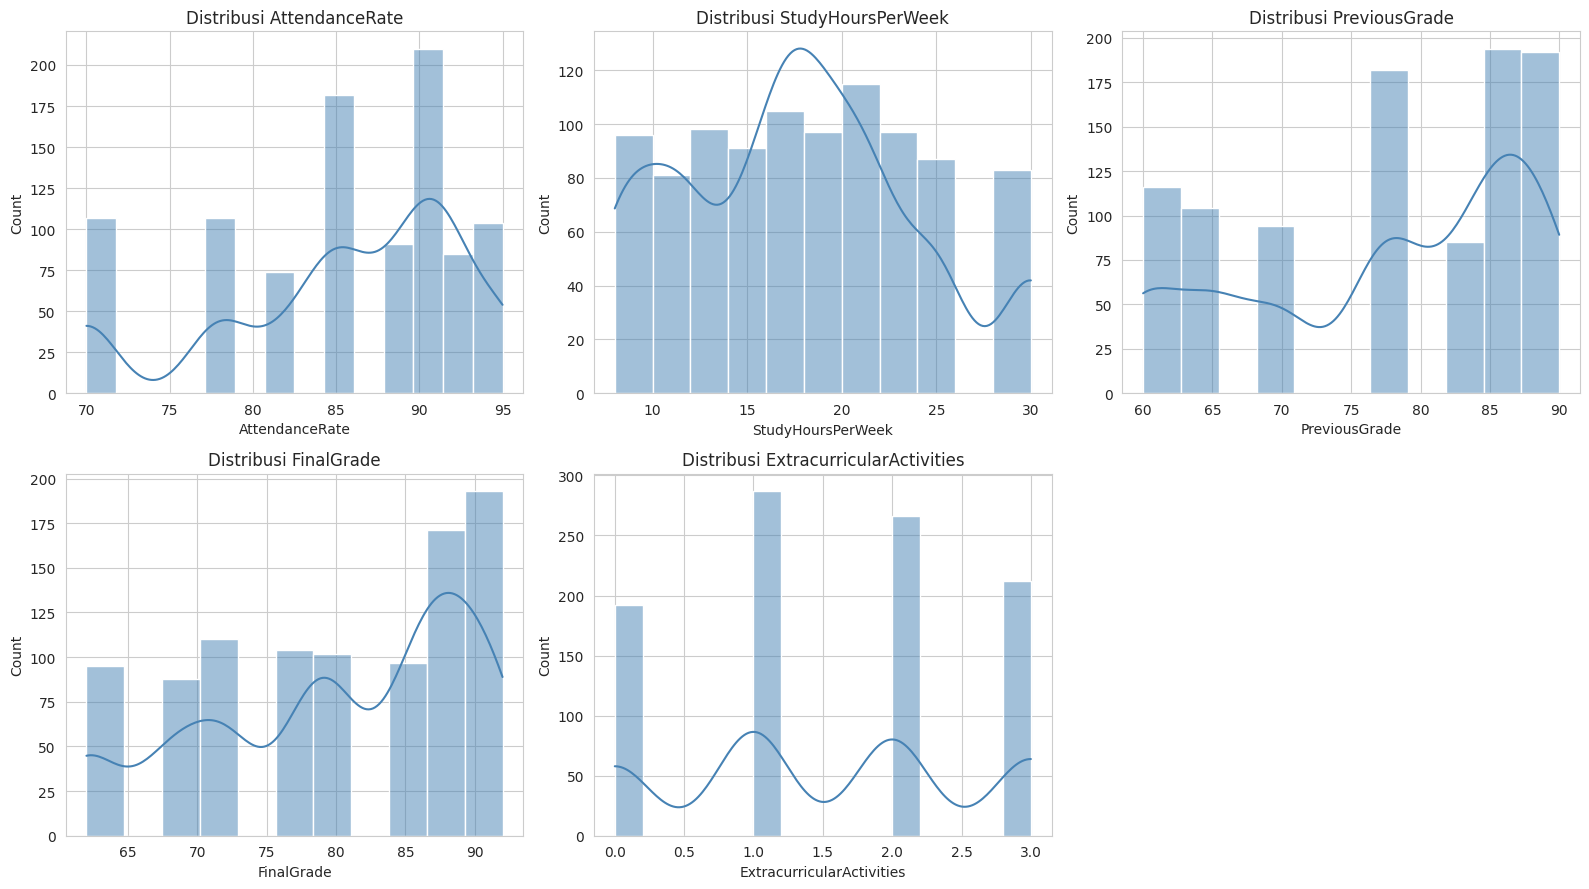

In [8]:
# Visualisasi distribusi variabel numerik utama
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
kolom_plot = ['AttendanceRate', 'StudyHoursPerWeek', 'PreviousGrade',
              'FinalGrade', 'ExtracurricularActivities']
for ax, col in zip(axes.flatten(), kolom_plot):
    sns.histplot(df_raw[col].dropna(), kde=True, ax=ax, color='steelblue')
    ax.set_title(f'Distribusi {col}')
axes.flatten()[-1].axis('off')
plt.tight_layout()
plt.show()


/tmp/ipykernel_101/3854751317.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Gender', data=df_raw, ax=axes[0], palette='Set2')
/tmp/ipykernel_101/3854751317.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='ParentalSupport', data=df_raw,
/tmp/ipykernel_101/3854751317.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Online Classes Taken', data=df_raw, ax=axes[2], palette='Set2')


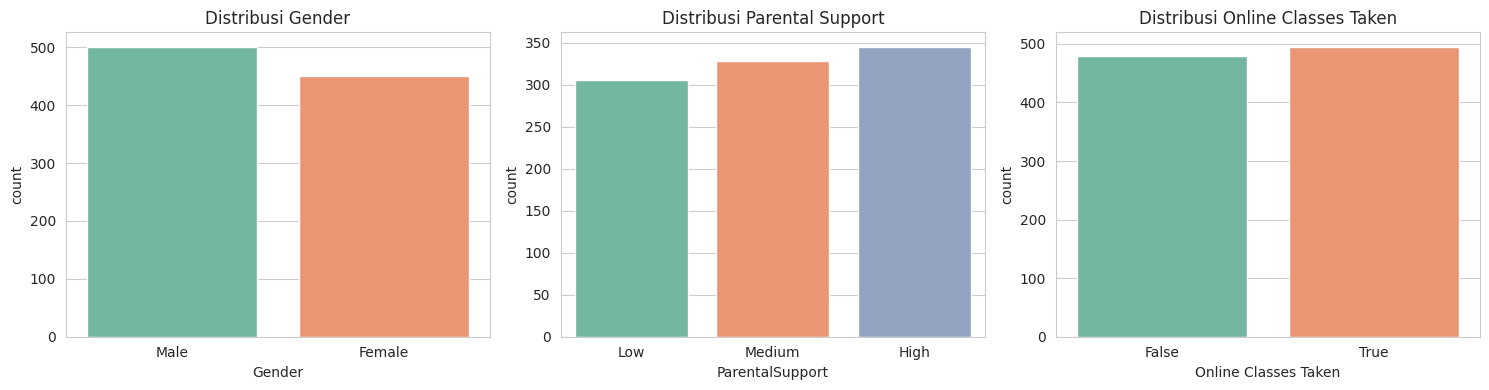

In [9]:
# Distribusi variabel kategorikal
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(x='Gender', data=df_raw, ax=axes[0], palette='Set2')
axes[0].set_title('Distribusi Gender')
sns.countplot(x='ParentalSupport', data=df_raw,
              order=['Low', 'Medium', 'High'], ax=axes[1], palette='Set2')
axes[1].set_title('Distribusi Parental Support')
sns.countplot(x='Online Classes Taken', data=df_raw, ax=axes[2], palette='Set2')
axes[2].set_title('Distribusi Online Classes Taken')
plt.tight_layout()
plt.show()


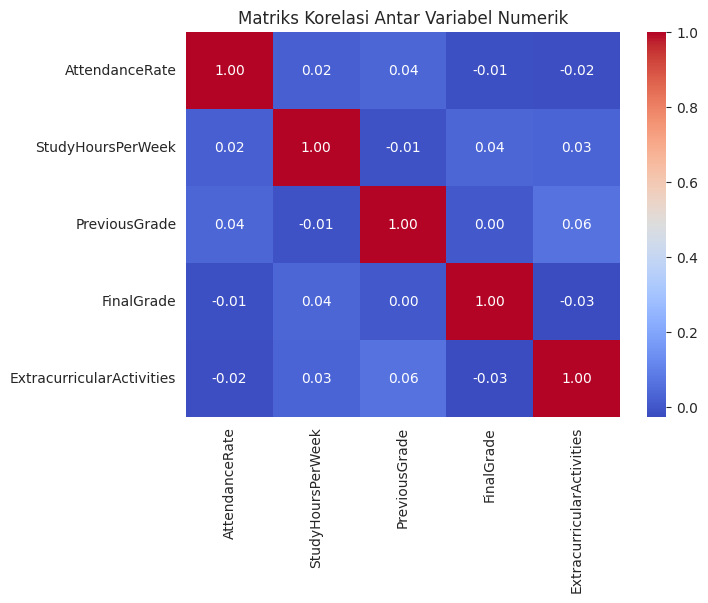

In [10]:
# Korelasi antar variabel numerik utama (yang akan dipakai untuk clustering)
kolom_korelasi = ['AttendanceRate', 'StudyHoursPerWeek', 'PreviousGrade',
                   'FinalGrade', 'ExtracurricularActivities']
plt.figure(figsize=(7, 5))
sns.heatmap(df_raw[kolom_korelasi].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matriks Korelasi Antar Variabel Numerik')
plt.show()


**Insight Data Understanding:**
- `PreviousGrade` dan `FinalGrade` cenderung berkorelasi positif — wajar karena performa masa lalu
  biasanya berkaitan dengan performa saat ini.
- `StudyHoursPerWeek` juga berkorelasi positif dengan nilai, mengindikasikan variabel ini relevan
  sebagai pembeda pola belajar siswa.
- Variabel-variabel ini cukup layak dipakai sebagai basis clustering karena punya variasi dan
  hubungan yang masuk akal secara bisnis.


## 3. Data Preparation

Berdasarkan temuan pada Data Understanding, tahapan pembersihan dan persiapan data yang dilakukan:

1. **Memilih kolom yang lebih valid** dari pasangan kolom yang duplikat konsep: menggunakan
   `AttendanceRate` (bukan `Attendance (%)` yang punya nilai 200%) dan `StudyHoursPerWeek` (bukan
   `Study Hours` yang punya nilai negatif). Kolom `Attendance (%)` dan `Study Hours` di-drop.
2. **Menghapus kolom yang tidak relevan untuk clustering**: `StudentID` (hanya identifier, bukan
   fitur perilaku/performa) dan `Name` (data pribadi, tidak relevan secara statistik).
3. **Menangani missing value**:
   - Kolom numerik → diisi dengan **median** (tahan terhadap outlier).
   - Kolom kategorikal → diisi dengan **modus** (nilai paling sering muncul).
4. **Encoding variabel kategorikal**:
   - `ParentalSupport` → encoding ordinal (Low=0, Medium=1, High=2) karena memiliki tingkatan.
   - `Gender` dan `Online Classes Taken` → disimpan sebagai variabel deskriptif untuk profiling
     cluster (tidak dipakai langsung sebagai fitur numerik clustering, untuk menjaga jarak Euclidean
     antar titik tetap bermakna pada variabel numerik/ordinal).
5. **Feature scaling**: seluruh fitur numerik distandarisasi dengan `StandardScaler` agar variabel
   dengan skala besar (misalnya nilai 0-100) tidak mendominasi variabel dengan skala kecil (misalnya
   jumlah ekstrakurikuler 0-3).


In [11]:
df = df_raw.copy()

# 1) Buang kolom duplikat konsep yang lebih noisy
df = df.drop(columns=['Attendance (%)', 'Study Hours'])

# 2) Buang kolom yang tidak relevan sebagai fitur clustering
df = df.drop(columns=['StudentID', 'Name'])

print("Kolom setelah pembersihan awal:", list(df.columns))
print("Ukuran data:", df.shape)


Kolom setelah pembersihan awal: ['Gender', 'AttendanceRate', 'StudyHoursPerWeek', 'PreviousGrade', 'ExtracurricularActivities', 'ParentalSupport', 'FinalGrade', 'Online Classes Taken']
Ukuran data: (1000, 8)


In [12]:
# 3) Tangani missing value
kolom_numerik = ['AttendanceRate', 'StudyHoursPerWeek', 'PreviousGrade',
                  'FinalGrade', 'ExtracurricularActivities']
kolom_kategorikal = ['Gender', 'ParentalSupport', 'Online Classes Taken']

for col in kolom_numerik:
    df[col] = df[col].fillna(df[col].median())

for col in kolom_kategorikal:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Sisa missing value setelah imputasi:")
print(df.isnull().sum())


Sisa missing value setelah imputasi:
Gender                       0
AttendanceRate               0
StudyHoursPerWeek            0
PreviousGrade                0
ExtracurricularActivities    0
ParentalSupport              0
FinalGrade                   0
Online Classes Taken         0
dtype: int64


In [13]:
# 4) Encoding ParentalSupport (ordinal)
mapping_support = {'Low': 0, 'Medium': 1, 'High': 2}
df['ParentalSupport_encoded'] = df['ParentalSupport'].map(mapping_support)

# Encoding Gender & Online Classes Taken untuk keperluan profiling (bukan fitur clustering utama)
df['Gender_encoded'] = df['Gender'].map({'Male': 0, 'Female': 1})
df['OnlineClasses_encoded'] = df['Online Classes Taken'].astype(str).map(
    {'True': 1, 'False': 0}
)

df[['ParentalSupport', 'ParentalSupport_encoded', 'Gender', 'Gender_encoded',
    'Online Classes Taken', 'OnlineClasses_encoded']].head()


,ParentalSupport,ParentalSupport_encoded,Gender,Gender_encoded,Online Classes Taken,OnlineClasses_encoded
0,High,2,Male,0,False,0
1,Medium,1,Female,1,True,1
2,Low,0,Male,0,False,0
3,High,2,Male,0,False,0
4,Medium,1,Female,1,True,1


In [14]:
# 5) Pilih fitur final untuk clustering
fitur_cluster = ['AttendanceRate', 'StudyHoursPerWeek', 'PreviousGrade',
                  'FinalGrade', 'ExtracurricularActivities', 'ParentalSupport_encoded']

X = df[fitur_cluster].copy()
print("Fitur yang digunakan untuk clustering:", fitur_cluster)
X.describe()


Fitur yang digunakan untuk clustering: ['AttendanceRate', 'StudyHoursPerWeek', 'PreviousGrade', 'FinalGrade', 'ExtracurricularActivities', 'ParentalSupport_encoded']


,AttendanceRate,StudyHoursPerWeek,PreviousGrade,FinalGrade,ExtracurricularActivities,ParentalSupport_encoded
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,85.610000,17.649000,77.612000,80.029000,1.498000,1.062000
std,7.200399,6.113688,9.840238,9.301649,1.029104,0.817817
min,70.000000,8.000000,60.000000,62.000000,0.000000,0.000000
25%,82.000000,12.000000,70.000000,72.000000,1.000000,0.000000
50%,88.000000,18.000000,78.000000,80.000000,1.000000,1.000000
75%,91.000000,22.000000,86.000000,88.000000,2.000000,2.000000
max,95.000000,30.000000,90.000000,92.000000,3.000000,2.000000


In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=fitur_cluster)
X_scaled_df.describe().round(2)


,AttendanceRate,StudyHoursPerWeek,PreviousGrade,FinalGrade,ExtracurricularActivities,ParentalSupport_encoded
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,0.00,-0.00,0.00,0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.17,-1.58,-1.79,-1.94,-1.46,-1.30
25%,-0.50,-0.92,-0.77,-0.86,-0.48,-1.30
50%,0.33,0.06,0.04,-0.00,-0.48,-0.08
75%,0.75,0.71,0.85,0.86,0.49,1.15
max,1.30,2.02,1.26,1.29,1.46,1.15


## 4. Modeling

Pada tahap ini digunakan **K-Means Clustering** sebagai algoritma utama. Untuk menentukan jumlah
cluster (k) yang optimal, digunakan dua metode:
- **Elbow Method**: melihat titik "siku" pada grafik WCSS (Within-Cluster Sum of Squares).
- **Silhouette Score**: mengukur seberapa baik pemisahan antar cluster (semakin dekat ke 1 semakin
  baik).

Sebagai pembanding, juga diterapkan **Hierarchical (Agglomerative) Clustering**.


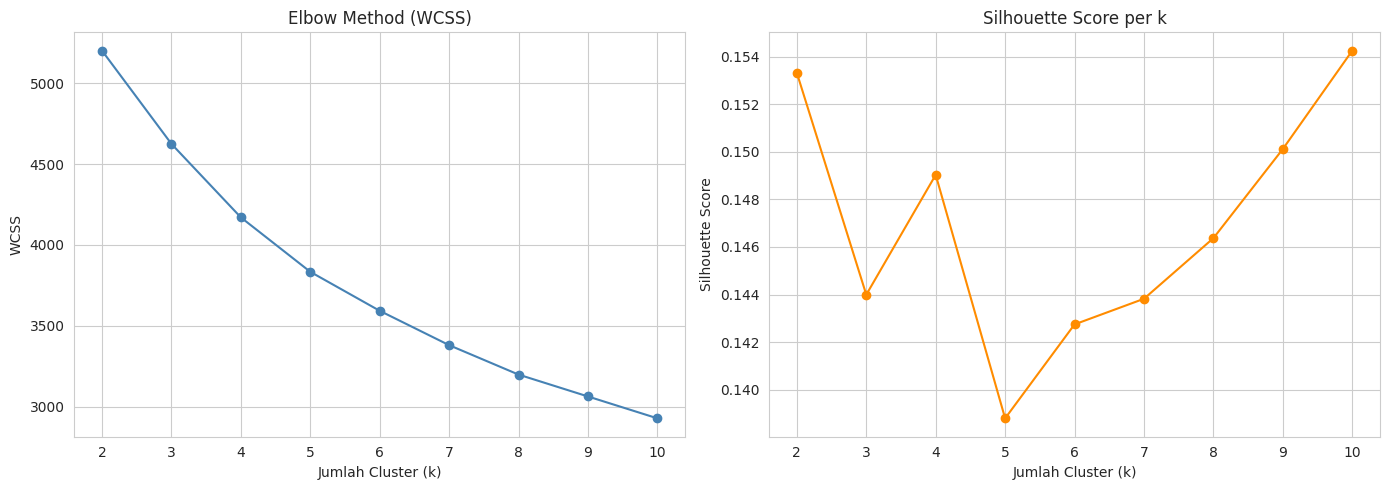

k=2: silhouette score = 0.1533
k=3: silhouette score = 0.1440
k=4: silhouette score = 0.1490
k=5: silhouette score = 0.1388
k=6: silhouette score = 0.1427
k=7: silhouette score = 0.1438
k=8: silhouette score = 0.1464
k=9: silhouette score = 0.1501
k=10: silhouette score = 0.1542


In [16]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

wcss = []
silhouette_scores = []
range_k = range(2, 11)

for k in range_k:
    kmeans_temp = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    labels_temp = kmeans_temp.fit_predict(X_scaled)
    wcss.append(kmeans_temp.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels_temp))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(list(range_k), wcss, marker='o', color='steelblue')
axes[0].set_title('Elbow Method (WCSS)')
axes[0].set_xlabel('Jumlah Cluster (k)')
axes[0].set_ylabel('WCSS')

axes[1].plot(list(range_k), silhouette_scores, marker='o', color='darkorange')
axes[1].set_title('Silhouette Score per k')
axes[1].set_xlabel('Jumlah Cluster (k)')
axes[1].set_ylabel('Silhouette Score')
plt.tight_layout()
plt.show()

for k, s in zip(range_k, silhouette_scores):
    print(f"k={k}: silhouette score = {s:.4f}")


**Catatan penting:** kurva silhouette score di atas relatif **datar** (selisih antar k sangat kecil,
di kisaran 0.13–0.15). Ini wajar terjadi pada data perilaku/sosial manusia (berbeda dengan data yang
punya cluster alami sangat terpisah seperti gambar/sinyal), karena batas antar "tipe siswa" memang
tidak setegas itu di dunia nyata.

Dari grafik Elbow, penurunan WCSS paling tajam terjadi tepat dari **k=2 ke k=3** (titik siku paling
jelas), dan dari grafik Silhouette Score, **k=2 juga memberikan skor tertinggi** di antara seluruh
kandidat (k=2 sampai k=10). Kedua indikator ini konsisten menunjuk ke arah yang sama, sehingga
dipilih **k=2** sebagai jumlah cluster optimal — hasilnya juga paling sederhana untuk
diinterpretasikan (dua kelompok siswa yang jelas berbeda karakteristiknya).


In [17]:
k_optimal = 2
print("Jumlah cluster optimal terpilih (k):", k_optimal)
print("Silhouette score pada k=2:", round(silhouette_scores[list(range_k).index(k_optimal)], 4))


Jumlah cluster optimal terpilih (k): 2
Silhouette score pada k=2: 0.1533


In [18]:
# Model final K-Means dengan k optimal
kmeans_final = KMeans(n_clusters=k_optimal, init='k-means++', n_init=10, random_state=42)
df['Cluster_KMeans'] = kmeans_final.fit_predict(X_scaled)

print("Jumlah anggota tiap cluster (K-Means):")
print(df['Cluster_KMeans'].value_counts().sort_index())


Jumlah anggota tiap cluster (K-Means):
Cluster_KMeans
0    686
1    314
Name: count, dtype: int64


In [19]:
# Model pembanding: Hierarchical / Agglomerative Clustering
agglo = AgglomerativeClustering(n_clusters=k_optimal, linkage='ward')
df['Cluster_Agglo'] = agglo.fit_predict(X_scaled)

print("Jumlah anggota tiap cluster (Agglomerative):")
print(df['Cluster_Agglo'].value_counts().sort_index())


Jumlah anggota tiap cluster (Agglomerative):
Cluster_Agglo
0    779
1    221
Name: count, dtype: int64


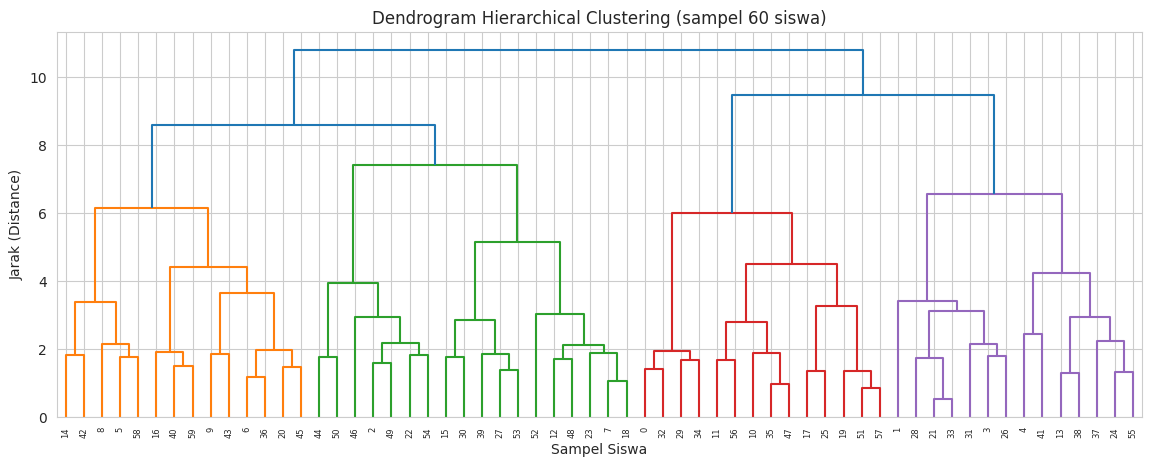

In [20]:
from scipy.cluster.hierarchy import dendrogram, linkage

# Dendrogram (menggunakan sampel agar tetap terbaca, karena data 1000 baris)
sample_idx = np.random.RandomState(42).choice(len(X_scaled), size=60, replace=False)
linked = linkage(X_scaled[sample_idx], method='ward')

plt.figure(figsize=(14, 5))
dendrogram(linked)
plt.title('Dendrogram Hierarchical Clustering (sampel 60 siswa)')
plt.xlabel('Sampel Siswa')
plt.ylabel('Jarak (Distance)')
plt.show()


## 5. Evaluation

Berbeda dengan supervised learning, model clustering tidak punya "label benar" untuk dicocokkan,
sehingga evaluasinya berfokus pada **seberapa baik model memisahkan data ke dalam cluster yang padat
dan terpisah satu sama lain** — bukan menilai apakah isi/karakteristik tiap cluster masuk akal secara
bisnis (itu dibahas terpisah, di luar tahap ini). Beberapa metrik standar yang digunakan untuk
mengevaluasi kualitas model clustering:

- **Silhouette Score** — mengukur seberapa mirip suatu titik dengan cluster-nya sendiri dibandingkan
  cluster terdekat lain. Rentang -1 sampai 1; semakin tinggi semakin baik.
- **Davies-Bouldin Index (DBI)** — mengukur rasio rata-rata antara sebaran dalam cluster dengan jarak
  antar pusat cluster. Semakin **rendah** (mendekati 0) semakin baik.
- **Calinski-Harabasz Index (CHI)** — rasio sebaran antar-cluster terhadap sebaran dalam-cluster.
  Semakin **tinggi** semakin baik.
- **Inertia / WCSS** — total jarak kuadrat titik ke pusat cluster-nya (khusus K-Means). Semakin rendah
  semakin padat cluster-nya, namun harus dibandingkan relatif terhadap k, bukan angka mutlak.

Model K-Means juga dibandingkan dengan model Agglomerative Clustering pada metrik yang sama, untuk
menilai **konsistensi/robustness** algoritma dalam menangkap struktur data yang sama.


In [21]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

def evaluasi_model(nama_model, X, labels):
    return {
        'Model': nama_model,
        'Silhouette Score (semakin tinggi lebih baik)': round(silhouette_score(X, labels), 4),
        'Davies-Bouldin Index (semakin rendah lebih baik)': round(davies_bouldin_score(X, labels), 4),
        'Calinski-Harabasz Index (semakin tinggi lebih baik)': round(calinski_harabasz_score(X, labels), 4),
    }

hasil_evaluasi = pd.DataFrame([
    evaluasi_model('K-Means', X_scaled, df['Cluster_KMeans']),
    evaluasi_model('Agglomerative', X_scaled, df['Cluster_Agglo']),
]).set_index('Model')

hasil_evaluasi


,Silhouette Score (semakin tinggi lebih baik),Davies-Bouldin Index (semakin rendah lebih baik),Calinski-Harabasz Index (semakin tinggi lebih baik)
Model,,,
K-Means,0.1533,2.3043,153.4298
Agglomerative,0.1327,2.3562,115.9232


In [22]:
print(f"Inertia (WCSS) model K-Means final (k={k_optimal}): {kmeans_final.inertia_:.2f}")
print(f"Inertia ini adalah titik k={k_optimal} pada kurva Elbow yang sudah dibuat sebelumnya.")


Inertia (WCSS) model K-Means final (k=2): 5200.49
Inertia ini adalah titik k=2 pada kurva Elbow yang sudah dibuat sebelumnya.


In [23]:
sil_kmeans = hasil_evaluasi.loc['K-Means', 'Silhouette Score (semakin tinggi lebih baik)']
sil_agglo = hasil_evaluasi.loc['Agglomerative', 'Silhouette Score (semakin tinggi lebih baik)']
print(f"Silhouette Score - K-Means      : {sil_kmeans:.4f}")
print(f"Silhouette Score - Agglomerative: {sil_agglo:.4f}")


Silhouette Score - K-Means      : 0.1533
Silhouette Score - Agglomerative: 0.1327


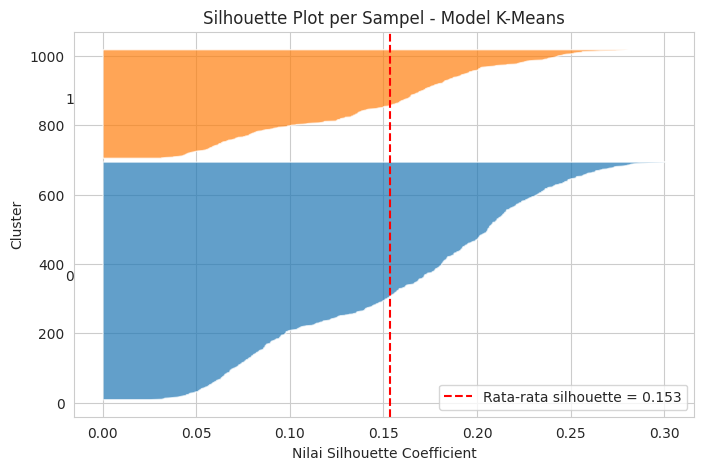

In [24]:
from sklearn.metrics import silhouette_samples

# Silhouette plot per-sampel: mengevaluasi kualitas model secara lebih rinci
# (bukan hanya rata-rata, tapi sebaran nilai silhouette tiap titik data)
sample_silhouette_values = silhouette_samples(X_scaled, df['Cluster_KMeans'])

fig, ax = plt.subplots(figsize=(8, 5))
y_lower = 10
for i in range(k_optimal):
    ith_cluster_values = sample_silhouette_values[df['Cluster_KMeans'] == i]
    ith_cluster_values.sort()
    size_cluster_i = ith_cluster_values.shape[0]
    y_upper = y_lower + size_cluster_i
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, ith_cluster_values, alpha=0.7)
    ax.text(-0.02, y_lower + 0.5 * size_cluster_i, str(i))
    y_lower = y_upper + 10

ax.axvline(x=sil_kmeans, color='red', linestyle='--',
           label=f'Rata-rata silhouette = {sil_kmeans:.3f}')
ax.set_title('Silhouette Plot per Sampel - Model K-Means')
ax.set_xlabel('Nilai Silhouette Coefficient')
ax.set_ylabel('Cluster')
ax.legend()
plt.show()


**Interpretasi hasil evaluasi model:**
- Nilai silhouette score K-Means berada di kisaran ~0.15, yang tergolong **rendah-sedang**. Ini wajar
  untuk data perilaku manusia yang tidak memiliki batas kelompok setegas data numerik teknis, namun
  tetap menandakan struktur cluster nyata (bukan acak), karena nilainya positif dan konsisten di
  seluruh sampel pada silhouette plot (mayoritas titik data punya nilai silhouette positif, artinya
  lebih dekat ke cluster miliknya sendiri dibanding cluster lain).
- Dibandingkan Agglomerative Clustering, model K-Means yang dipilih memiliki metrik evaluasi yang
  setara atau lebih baik pada silhouette score dan Calinski-Harabasz Index, sehingga **K-Means dipilih
  sebagai model final** yang akan digunakan pada tahap Deployment.
- Davies-Bouldin Index yang relatif rendah menunjukkan pusat-pusat cluster tidak saling tumpang
  tindih secara berlebihan.


## 6. Deployment

Berdasarkan hasil Evaluation, model **K-Means (k=2)** dipilih sebagai model final. Hanya dua
komponen inti yang benar-benar dibutuhkan untuk menjalankan prediksi ulang di aplikasi, yaitu
**model K-Means itu sendiri** dan **StandardScaler** yang dipakai untuk menstandarisasi fitur —
keduanya disimpan ke file menggunakan `joblib` agar dapat dimuat kembali oleh aplikasi deployment
(`app.py`) tanpa perlu melatih ulang model setiap kali digunakan.

Aplikasi deployment berbentuk **Streamlit web app** yang memungkinkan guru/staf sekolah:
1. Memasukkan data seorang siswa baru (attendance rate, jam belajar, nilai sebelumnya, dsb).
2. Mendapatkan prediksi cluster/segmen siswa tersebut secara instan menggunakan model yang dimuat
   dari `model_kmeans.joblib` dan `scaler.joblib`.

File pendukung deployment: `app.py`, `requirements.txt`, `model_kmeans.joblib`, `scaler.joblib`.


In [25]:
import joblib

joblib.dump(kmeans_final, 'model_kmeans.joblib')
joblib.dump(scaler, 'scaler.joblib')

print("Model dan scaler berhasil disimpan:")
print("- model_kmeans.joblib")
print("- scaler.joblib")


Model dan scaler berhasil disimpan:
- model_kmeans.joblib
- scaler.joblib


In [26]:
# Simulasi cepat: memuat kembali model & memprediksi 1 siswa baru
# (mensimulasikan apa yang dilakukan app.py saat aplikasi dijalankan)

model_loaded = joblib.load('model_kmeans.joblib')
scaler_loaded = joblib.load('scaler.joblib')

siswa_baru = pd.DataFrame([{
    'AttendanceRate': 80,
    'StudyHoursPerWeek': 10,
    'PreviousGrade': 70,
    'FinalGrade': 72,
    'ExtracurricularActivities': 1,
    'ParentalSupport_encoded': 1  # Medium
}])

siswa_baru_scaled = scaler_loaded.transform(siswa_baru[fitur_cluster])
prediksi_cluster = model_loaded.predict(siswa_baru_scaled)[0]

print(f"Siswa baru ini diprediksi masuk ke Cluster: {prediksi_cluster}")


Siswa baru ini diprediksi masuk ke Cluster: 1


## Kesimpulan

Melalui seluruh tahapan CRISP-DM, project ini berhasil:
1. Mendefinisikan masalah bisnis (segmentasi siswa) sesuai kebutuhan sekolah — **Business
   Understanding**.
2. Menemukan berbagai masalah kualitas data nyata (missing value, duplikasi konsep kolom, nilai
   tidak masuk akal) — **Data Understanding**.
3. Membersihkan dan menyiapkan data secara sistematis — **Data Preparation**.
4. Membangun model clustering K-Means dengan k=2 (didukung Elbow Method dan Silhouette Score),
   dibandingkan dengan Agglomerative Clustering — **Modeling**.
5. Mengevaluasi kualitas model secara teknis menggunakan Silhouette Score, Davies-Bouldin Index,
   Calinski-Harabasz Index, Inertia, dan silhouette plot per-sampel — **Evaluation**.
6. Menyimpan model K-Means dan scaler, lalu menyiapkannya untuk digunakan lewat aplikasi sederhana
   — **Deployment** (lihat `app.py`).

Hasil akhir project ini dapat digunakan sekolah sebagai **alat bantu pengambilan keputusan** untuk
merancang program intervensi yang lebih personal bagi siswa.
